# Practical 3: Linear Regression and Feature Engineering

**Datasets:** `Salary_Data.csv` and `penguins_size.csv`

**Name :** Parth Isekar

**PRN** 202401080062



## Imports and common settings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

# Folder for figures created by this notebook
from pathlib import Path
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


# Dataset 1: Salary_Data.csv — Simple Linear Regression

## Q1. Load and inspect Salary_Data.csv

The dataset contains one input feature (`YearsExperience`) and one continuous target (`Salary`). We inspect its dimensions, first five rows, descriptive statistics and missing values before modelling.

In [2]:
salary = pd.read_csv("Salary_Data.csv")

print("Shape:", salary.shape)
print("\nFirst five rows:")
print(salary.head())
print("\nDescriptive statistics:")
print(salary.describe())
print("\nMissing values in each column:")
print(salary.isnull().sum())

Shape: (30, 2)

First five rows:
   YearsExperience  Salary
0              1.1   39343
1              1.3   46205
2              1.5   37731
3              2.0   43525
4              2.2   39891

Descriptive statistics:
       YearsExperience         Salary
count        30.000000      30.000000
mean          5.313333   76003.000000
std           2.837888   27414.429785
min           1.100000   37731.000000
25%           3.200000   56720.750000
50%           4.700000   65237.000000
75%           7.700000  100544.750000
max          10.500000  122391.000000

Missing values in each column:
YearsExperience    0
Salary             0
dtype: int64


## Q2. Scatter plot and Pearson correlation

Pearson's correlation coefficient measures the direction and strength of the linear relationship. A value close to +1 indicates a strong positive linear relationship.

Pearson correlation coefficient: 0.978242


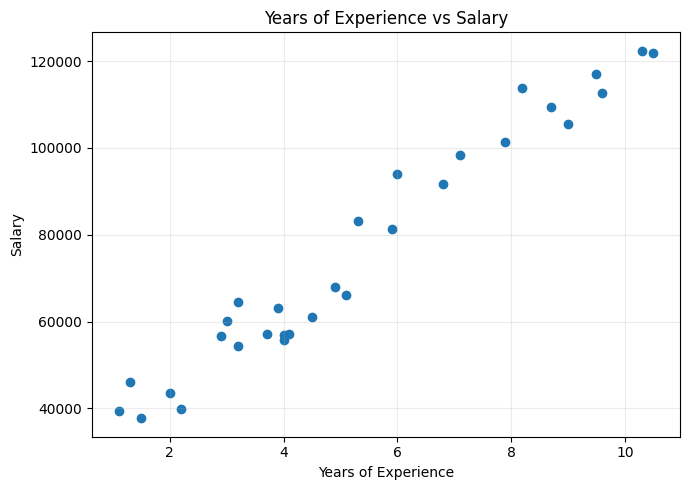

Comment: There is a strong positive linear relationship: salary generally increases as experience increases.


In [3]:
correlation = salary["YearsExperience"].corr(salary["Salary"])
print(f"Pearson correlation coefficient: {correlation:.6f}")

plt.figure(figsize=(7, 5))
plt.scatter(salary["YearsExperience"], salary["Salary"])
plt.title("Years of Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "salary_scatter.png", dpi=150)
plt.show()

if correlation > 0.7:
    print("Comment: There is a strong positive linear relationship: salary generally increases as experience increases.")
elif correlation > 0:
    print("Comment: There is a positive linear relationship, but it is not very strong.")
else:
    print("Comment: The linear relationship is weak or negative.")

## Q3. Train-test split and reshape

The question specifies `train_size=2/3` and `random_state=0`. The feature is first stored as a one-dimensional array and then reshaped into a two-dimensional column because scikit-learn expects input features in `(number_of_rows, number_of_features)` form.

In [4]:
X = salary["YearsExperience"].values
y = salary["Salary"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=2/3, random_state=0
)

X_train = X_train.reshape(-1, 1)
X_test = X_test.reshape(-1, 1)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (20, 1)
Testing feature shape: (10, 1)
Training target shape: (20,)
Testing target shape: (10,)


## Q4. Fit LinearRegression and write the equation

For simple linear regression, the fitted equation is:

\[\widehat{Salary} = b_0 + b_1(YearsExperience)\]

where `b1` is the slope (coefficient) and `b0` is the intercept.

In [5]:
salary_model = LinearRegression()
salary_model.fit(X_train, y_train)

salary_slope = float(salary_model.coef_[0])
salary_intercept = float(salary_model.intercept_)

print(f"Slope: {salary_slope:.4f}")
print(f"Intercept: {salary_intercept:.4f}")
print(
    f"Fitted equation: Salary = {salary_intercept:.2f} "
    f"+ ({salary_slope:.2f} × YearsExperience)"
)

Slope: 9345.9424
Intercept: 26816.1922
Fitted equation: Salary = 26816.19 + (9345.94 × YearsExperience)


## Q5. Predict test salaries, 5-year salary and 12-year salary

The model predicts the held-out test records. It also predicts salaries for 5 and 12 years of experience. The largest experience value in the dataset is checked to identify extrapolation.

In [6]:
y_pred = salary_model.predict(X_test)

salary_test_results = pd.DataFrame({
    "YearsExperience": X_test.ravel(),
    "ActualSalary": y_test,
    "PredictedSalary": y_pred
}).sort_values("YearsExperience")

print("Predictions for test records:")
print(salary_test_results.to_string(index=False))

experience_values = np.array([[5], [12]])
experience_predictions = salary_model.predict(experience_values)
print(f"\nPredicted salary at 5 years: {experience_predictions[0]:.2f}")
print(f"Predicted salary at 12 years: {experience_predictions[1]:.2f}")
print(f"Observed experience range: {salary['YearsExperience'].min()} to {salary['YearsExperience'].max()} years")
print("Comment: 5 years is within the observed range, so it is an interpolation. 12 years is beyond the maximum observed 10.5 years, so it is an extrapolation and is less reliable.")

Predictions for test records:
 YearsExperience  ActualSalary  PredictedSalary
             1.5         37731     40835.105909
             3.9         63218     63265.367772
             4.0         55794     64199.962017
             4.1         57081     65134.556261
             5.3         83088     76349.687193
             7.9        101302    100649.137545
             8.7        109431    108125.891499
             9.5        116969    115602.645454
             9.6        112635    116537.239698
            10.3        122391    123079.399408

Predicted salary at 5 years: 73545.90
Predicted salary at 12 years: 138967.50
Observed experience range: 1.1 to 10.5 years
Comment: 5 years is within the observed range, so it is an interpolation. 12 years is beyond the maximum observed 10.5 years, so it is an extrapolation and is less reliable.


## Q6. Training and test plots with the fitted regression line

Two subplots are used: one shows the training observations and fitted line, and the other shows the test observations against the same fitted line. The line is drawn over sorted experience values so it appears continuous.

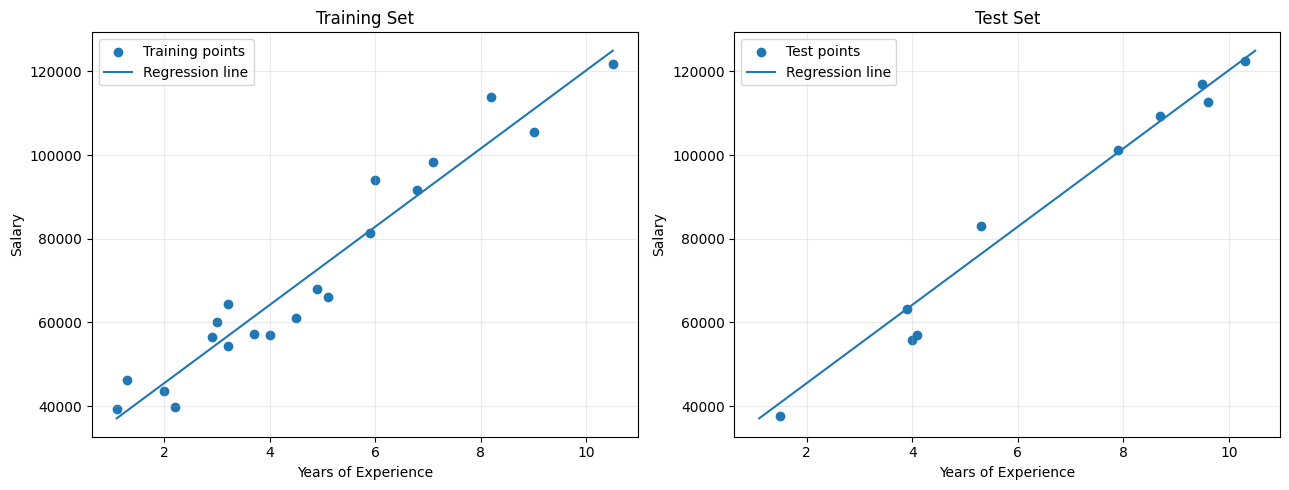

In [7]:
x_line = np.linspace(salary["YearsExperience"].min(), salary["YearsExperience"].max(), 100).reshape(-1, 1)
y_line = salary_model.predict(x_line)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X_train.ravel(), y_train, label="Training points")
axes[0].plot(x_line.ravel(), y_line, label="Regression line")
axes[0].set_title("Training Set")
axes[0].set_xlabel("Years of Experience")
axes[0].set_ylabel("Salary")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].scatter(X_test.ravel(), y_test, label="Test points")
axes[1].plot(x_line.ravel(), y_line, label="Regression line")
axes[1].set_title("Test Set")
axes[1].set_xlabel("Years of Experience")
axes[1].set_ylabel("Salary")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "salary_train_test_regression.png", dpi=150)
plt.show()

## Q7. Calculate MSE and MAE manually; verify with scikit-learn

The manual functions use the definitions:

- MSE = mean of squared prediction errors.
- MAE = mean of absolute prediction errors.
- RMSE = square root of MSE.
- R² compares the model's squared error with the variation in the actual target values.

In [8]:
def calculate_mse(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    return np.mean((actual - predicted) ** 2)


def calculate_mae(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    return np.mean(np.abs(actual - predicted))

mse_manual = calculate_mse(y_test, y_pred)
mae_manual = calculate_mae(y_test, y_pred)
rmse_value = np.sqrt(mse_manual)
r2_value = r2_score(y_test, y_pred)

mse_sklearn = mean_squared_error(y_test, y_pred)
mae_sklearn = mean_absolute_error(y_test, y_pred)

metrics_salary = pd.DataFrame({
    "Metric": ["MSE", "MAE", "RMSE", "R2"],
    "Manual / calculated value": [mse_manual, mae_manual, rmse_value, r2_value],
    "scikit-learn value (where applicable)": [mse_sklearn, mae_sklearn, np.nan, r2_score(y_test, y_pred)]
})
print(metrics_salary.to_string(index=False))
print("\nMSE manual matches sklearn:", np.isclose(mse_manual, mse_sklearn))
print("MAE manual matches sklearn:", np.isclose(mae_manual, mae_sklearn))

Metric  Manual / calculated value  scikit-learn value (where applicable)
   MSE               2.102604e+07                           2.102604e+07
   MAE               3.426427e+03                           3.426427e+03
  RMSE               4.585416e+03                                    NaN
    R2               9.749154e-01                           9.749154e-01

MSE manual matches sklearn: True
MAE manual matches sklearn: True


## Q8. Residual plot and linear-regression assumptions

A residual is `actual - predicted`. A useful residual plot has points scattered around the zero line without a strong curve or funnel pattern. This plot is a visual diagnostic; it cannot by itself prove every regression assumption.

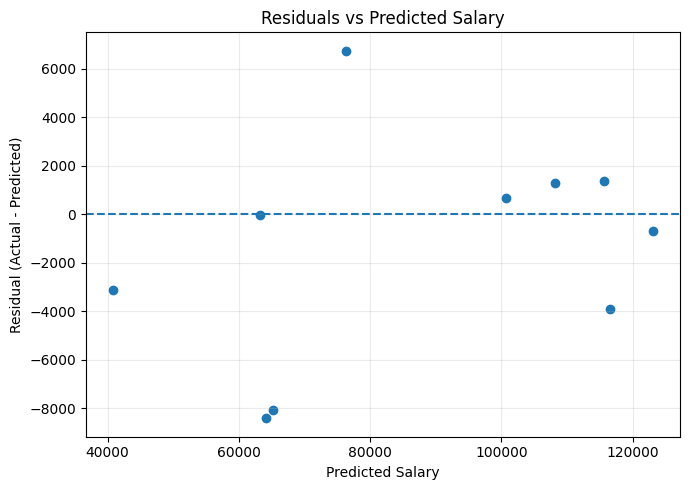

Mean residual: -1413.90
Comment: Inspect whether residuals are randomly distributed around zero. This small test sample does not show a strong systematic curve or clear funnel pattern, but the plot alone cannot establish independence or normality. A larger sample and additional diagnostics would be needed for a complete assumption check.


In [9]:
residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals)
plt.axhline(y=0, linestyle="--")
plt.title("Residuals vs Predicted Salary")
plt.xlabel("Predicted Salary")
plt.ylabel("Residual (Actual - Predicted)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "salary_residual_plot.png", dpi=150)
plt.show()

print(f"Mean residual: {residuals.mean():.2f}")
print("Comment: Inspect whether residuals are randomly distributed around zero. This small test sample does not show a strong systematic curve or clear funnel pattern, but the plot alone cannot establish independence or normality. A larger sample and additional diagnostics would be needed for a complete assumption check.")

## Q9. Ordinary Least Squares (OLS) from scratch using NumPy

The slope and intercept are calculated using the closed-form simple-regression formulas from the study guide:

\[b_1=\frac{\sum (x_i-\bar{x})(y_i-\bar{y})}{\sum (x_i-\bar{x})^2}, \qquad b_0=\bar{y}-b_1\bar{x}\]

The calculation uses the training data only, then compares the results with scikit-learn.

In [10]:
x_train_1d = X_train.ravel()
x_mean = x_train_1d.mean()
y_mean = y_train.mean()

ols_slope = np.sum((x_train_1d - x_mean) * (y_train - y_mean)) / np.sum((x_train_1d - x_mean) ** 2)
ols_intercept = y_mean - ols_slope * x_mean

print(f"OLS from NumPy - slope: {ols_slope:.10f}")
print(f"OLS from NumPy - intercept: {ols_intercept:.10f}")
print(f"scikit-learn - slope: {salary_slope:.10f}")
print(f"scikit-learn - intercept: {salary_intercept:.10f}")
print("Slope values match:", np.isclose(ols_slope, salary_slope))
print("Intercept values match:", np.isclose(ols_intercept, salary_intercept))

OLS from NumPy - slope: 9345.9424431224
OLS from NumPy - intercept: 26816.1922440312
scikit-learn - slope: 9345.9424431224
scikit-learn - intercept: 26816.1922440312
Slope values match: True
Intercept values match: True


## Q10. Repeat the split with five random_state values

The same `train_size=2/3` is used for random states 0 to 4. Since the dataset is small, each split contains only 10 test rows; changing which observations are held out can change R².

In [11]:
random_state_results = []

for state in [0, 1, 2, 3, 4]:
    X_tr, X_te, y_tr, y_te = train_test_split(
        salary["YearsExperience"].values,
        salary["Salary"].values,
        train_size=2/3,
        random_state=state
    )
    model = LinearRegression()
    model.fit(X_tr.reshape(-1, 1), y_tr)
    pred = model.predict(X_te.reshape(-1, 1))
    random_state_results.append({
        "random_state": state,
        "training_rows": len(X_tr),
        "testing_rows": len(X_te),
        "R2": r2_score(y_te, pred)
    })

random_state_table = pd.DataFrame(random_state_results)
print(random_state_table.to_string(index=False))
print("\nComment: R2 varies because each random state selects a different training and test sample. With only 30 rows, the composition of the 10-row test set has a noticeable effect on the score.")

 random_state  training_rows  testing_rows       R2
            0             20            10 0.974915
            1             20            10 0.924085
            2             20            10 0.904180
            3             20            10 0.943436
            4             20            10 0.946808

Comment: R2 varies because each random state selects a different training and test sample. With only 30 rows, the composition of the 10-row test set has a noticeable effect on the score.


# Dataset 2: penguins_size.csv — Feature Engineering

## Q11. Load the penguins dataset and count missing values

In [12]:
penguins = pd.read_csv("penguins_size.csv")

print("Shape:", penguins.shape)
print("\nFirst five rows:")
print(penguins.head())
print("\nMissing values in each column:")
print(penguins.isnull().sum())

Shape: (344, 7)

First five rows:
  species     island  culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g     sex
0  Adelie  Torgersen              39.1             18.7              181.0       3750.0    MALE
1  Adelie  Torgersen              39.5             17.4              186.0       3800.0  FEMALE
2  Adelie  Torgersen              40.3             18.0              195.0       3250.0  FEMALE
3  Adelie  Torgersen               NaN              NaN                NaN          NaN     NaN
4  Adelie  Torgersen              36.7             19.3              193.0       3450.0  FEMALE

Missing values in each column:
species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64


## Q12. Identify and remove invalid entries in `sex`

The valid non-missing values are `MALE` and `FEMALE`. The supplied file contains a literal `.` in the `sex` column; this is an invalid category and its row is removed programmatically. Missing values (`NaN`) are retained here because Q13 asks us to demonstrate imputation.

In [13]:
penguins["sex"] = penguins["sex"].astype("string").str.strip().str.upper()
valid_sex_values = ["MALE", "FEMALE"]
invalid_sex_mask = penguins["sex"].notna() & ~penguins["sex"].isin(valid_sex_values)

print("Invalid non-missing sex entries:")
print(penguins.loc[invalid_sex_mask, ["species", "island", "sex"]])
print("Number of invalid rows:", int(invalid_sex_mask.sum()))

penguins_valid = penguins.loc[~invalid_sex_mask].copy()
print("Shape after removing invalid sex rows:", penguins_valid.shape)
print("Missing sex entries retained for the imputation exercise:", penguins_valid["sex"].isna().sum())

Invalid non-missing sex entries:
    species  island sex
336  Gentoo  Biscoe   .
Number of invalid rows: 1
Shape after removing invalid sex rows: (343, 7)
Missing sex entries retained for the imputation exercise: 10


## Q13. Create three cleaned versions of the dataset

**(a) Drop missing rows:** remove any row containing a missing value.

**(b) Mean/mode imputation:** fill numeric columns with their column mean and fill missing `sex` values with the mode.

**(c) Species-wise median imputation:** fill each numeric column using the median calculated within the same species. The question only specifies numeric median imputation, so missing `sex` values are left unchanged in version (c).

In [14]:
numeric_columns = [
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

# (a) Complete-case dataset
penguins_dropna = penguins_valid.dropna().copy()

# (b) Numeric mean imputation and sex mode imputation
penguins_mean_imputed = penguins_valid.copy()
for column in numeric_columns:
    penguins_mean_imputed[column] = penguins_mean_imputed[column].fillna(
        penguins_mean_imputed[column].mean()
    )
sex_mode = penguins_mean_imputed["sex"].mode(dropna=True)[0]
penguins_mean_imputed["sex"] = penguins_mean_imputed["sex"].fillna(sex_mode)

# (c) Numeric median imputation within each species
penguins_species_median = penguins_valid.copy()
for column in numeric_columns:
    penguins_species_median[column] = penguins_species_median.groupby("species")[column].transform(
        lambda values: values.fillna(values.median())
    )

print("(a) Drop missing rows:", penguins_dropna.shape)
print("(b) Numeric mean + sex mode imputation:", penguins_mean_imputed.shape)
print("(c) Species-wise numeric median imputation:", penguins_species_median.shape)

print("\nRemaining missing values in (a):\n", penguins_dropna.isnull().sum())
print("\nRemaining missing values in (b):\n", penguins_mean_imputed.isnull().sum())
print("\nRemaining missing values in (c):\n", penguins_species_median.isnull().sum())
print("\nMode used for sex imputation:", sex_mode)

(a) Drop missing rows: (333, 7)
(b) Numeric mean + sex mode imputation: (343, 7)
(c) Species-wise numeric median imputation: (343, 7)

Remaining missing values in (a):
 species              0
island               0
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

Remaining missing values in (b):
 species              0
island               0
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

Remaining missing values in (c):
 species               0
island                0
culmen_length_mm      0
culmen_depth_mm       0
flipper_length_mm     0
body_mass_g           0
sex                  10
dtype: int64

Mode used for sex imputation: MALE


## Q14. Species-wise mean body mass and flipper length

Pandas `groupby()` calculates the mean separately for Adelie, Chinstrap and Gentoo. `mean()` ignores missing numeric observations. The bar chart compares both measurements by species.

           body_mass_g  flipper_length_mm
species                                  
Adelie     3700.662252         189.953642
Chinstrap  3733.088235         195.823529
Gentoo     5077.663934         217.188525


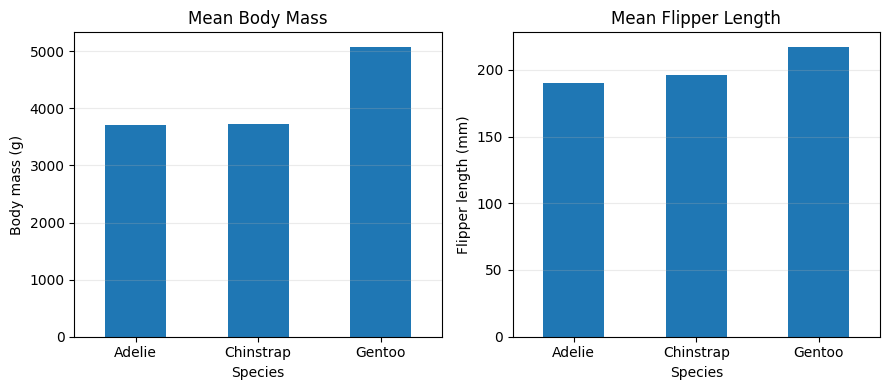

Comment: Gentoo penguins have the highest mean body mass and mean flipper length in this dataset.


In [15]:
species_means = penguins_valid.groupby("species")[["body_mass_g", "flipper_length_mm"]].mean()
print(species_means)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
species_means["body_mass_g"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Mean Body Mass")
axes[0].set_xlabel("Species")
axes[0].set_ylabel("Body mass (g)")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.25)

species_means["flipper_length_mm"].plot(kind="bar", ax=axes[1])
axes[1].set_title("Mean Flipper Length")
axes[1].set_xlabel("Species")
axes[1].set_ylabel("Flipper length (mm)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "penguin_species_means.png", dpi=150)
plt.show()

print("Comment: Gentoo penguins have the highest mean body mass and mean flipper length in this dataset.")

## Q15. Compare Pandas category codes and LabelEncoder

The columns `species`, `island` and `sex` are converted to Pandas `category` dtype. Their category codes are compared with scikit-learn's `LabelEncoder`. Missing `sex` values receive code `-1` in Pandas; LabelEncoder is compared only on non-missing entries.

In [16]:
categorical_columns = ["species", "island", "sex"]
penguins_categories = penguins_valid.copy()

for column in categorical_columns:
    penguins_categories[column] = penguins_categories[column].astype("category")

category_code_table = pd.DataFrame(index=penguins_categories.index)
encoding_comparison = []

for column in categorical_columns:
    category_codes = penguins_categories[column].cat.codes
    category_code_table[column + "_cat_code"] = category_codes

    non_missing_mask = penguins_categories[column].notna()
    label_encoder = LabelEncoder()
    label_codes = label_encoder.fit_transform(penguins_categories.loc[non_missing_mask, column].astype(str))

    same_codes = np.array_equal(
        category_codes.loc[non_missing_mask].to_numpy(),
        label_codes
    )
    encoding_comparison.append({
        "column": column,
        "Pandas categories": list(penguins_categories[column].cat.categories),
        "LabelEncoder classes": list(label_encoder.classes_),
        "codes match on non-missing rows": same_codes
    })

print("First five rows of Pandas category codes:")
print(category_code_table.head())
print("\nEncoding comparison:")
for result in encoding_comparison:
    print(result)

print("\nNote: Category codes are useful for demonstrating encoding, but nominal categories should generally be one-hot encoded when used in a linear model because the integer codes can imply an artificial order.")

First five rows of Pandas category codes:
   species_cat_code  island_cat_code  sex_cat_code
0                 0                2             1
1                 0                2             0
2                 0                2             0
3                 0                2            -1
4                 0                2             0

Encoding comparison:
{'column': 'species', 'Pandas categories': ['Adelie', 'Chinstrap', 'Gentoo'], 'LabelEncoder classes': ['Adelie', 'Chinstrap', 'Gentoo'], 'codes match on non-missing rows': True}
{'column': 'island', 'Pandas categories': ['Biscoe', 'Dream', 'Torgersen'], 'LabelEncoder classes': ['Biscoe', 'Dream', 'Torgersen'], 'codes match on non-missing rows': True}
{'column': 'sex', 'Pandas categories': ['FEMALE', 'MALE'], 'LabelEncoder classes': ['FEMALE', 'MALE'], 'codes match on non-missing rows': True}

Note: Category codes are useful for demonstrating encoding, but nominal categories should generally be one-hot encoded when used in 

## Q16. One-hot encode categorical features and create the feature matrix

The required `island` and `sex` columns are one-hot encoded with `drop_first=True`. `species` is also one-hot encoded because it is a nominal category and is needed in the multiple-regression model. The numeric features are joined with these encoded columns. The displayed matrix includes `body_mass_g` so the original four numeric columns remain visible; it is removed from the predictors when the model is trained.

In [17]:
# Use complete rows so the final feature matrix has no missing values.
penguins_for_features = penguins_dropna.copy()

island_sex_encoded = pd.get_dummies(
    penguins_for_features[["island", "sex"]],
    drop_first=True,
    dtype=int
)
species_encoded = pd.get_dummies(
    penguins_for_features["species"],
    prefix="species",
    drop_first=True,
    dtype=int
)

final_feature_matrix = pd.concat(
    [penguins_for_features[numeric_columns], species_encoded, island_sex_encoded],
    axis=1
)

print("Encoded island and sex columns:")
print(island_sex_encoded.head())
print("\nFinal feature matrix shape:", final_feature_matrix.shape)
print("Final feature matrix (first five rows):")
print(final_feature_matrix.head())

Encoded island and sex columns:
   island_Dream  island_Torgersen  sex_MALE
0             0                 1         1
1             0                 1         0
2             0                 1         0
4             0                 1         0
5             0                 1         1

Final feature matrix shape: (333, 9)
Final feature matrix (first five rows):
   culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  species_Chinstrap  species_Gentoo  island_Dream  island_Torgersen  \
0              39.1             18.7              181.0       3750.0                  0               0             0                 1   
1              39.5             17.4              186.0       3800.0                  0               0             0                 1   
2              40.3             18.0              195.0       3250.0                  0               0             0                 1   
4              36.7             19.3              193.0       3450.0  

## Q17. Scale four numeric columns using StandardScaler and MinMaxScaler

The four numeric columns are scaled. To avoid data leakage, the dataset is split first; each scaler is fitted only on the training rows and is then used to transform both training and test rows. The summary tables below describe the training data before and after scaling.

In [18]:
# Keep this split for Q17-Q19 so both penguin regression models use the same rows.
peng_train, peng_test = train_test_split(
    penguins_dropna,
    train_size=2/3,
    random_state=0
)

numeric_train = peng_train[numeric_columns]
numeric_test = peng_test[numeric_columns]

standard_scaler = StandardScaler()
standard_train = pd.DataFrame(
    standard_scaler.fit_transform(numeric_train),
    columns=numeric_columns,
    index=numeric_train.index
)
standard_test = pd.DataFrame(
    standard_scaler.transform(numeric_test),
    columns=numeric_columns,
    index=numeric_test.index
)

minmax_scaler = MinMaxScaler()
minmax_train = pd.DataFrame(
    minmax_scaler.fit_transform(numeric_train),
    columns=numeric_columns,
    index=numeric_train.index
)
minmax_test = pd.DataFrame(
    minmax_scaler.transform(numeric_test),
    columns=numeric_columns,
    index=numeric_test.index
)

print("Training numeric columns BEFORE scaling:")
print(numeric_train.describe())
print("\nTraining numeric columns AFTER StandardScaler:")
print(standard_train.describe())
print("\nTraining numeric columns AFTER MinMaxScaler:")
print(minmax_train.describe())
print("\nFirst five StandardScaler test rows (transformed using training scaler):")
print(standard_test.head())
print("\nFirst five MinMaxScaler test rows (transformed using training scaler):")
print(minmax_test.head())

Training numeric columns BEFORE scaling:
       culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g
count        222.000000       222.000000         222.000000   222.000000
mean          44.449099        17.226126         201.662162  4255.067568
std            5.513215         2.021724          13.793838   807.592433
min           34.000000        13.100000         172.000000  2700.000000
25%           39.625000        15.600000         190.000000  3650.000000
50%           45.200000        17.550000         198.000000  4100.000000
75%           49.175000        18.800000         213.000000  4850.000000
max           59.600000        21.500000         230.000000  6300.000000

Training numeric columns AFTER StandardScaler:
       culmen_length_mm  culmen_depth_mm  flipper_length_mm   body_mass_g
count      2.220000e+02     2.220000e+02       2.220000e+02  2.220000e+02
mean      -2.880579e-16     3.840772e-16       6.001206e-17  7.601527e-17
std        1.002260e+00     1.00

## Q18. Simple linear regression: body mass from flipper length

The model uses `flipper_length_mm` as the single feature and `body_mass_g` as the target. The same train-test split defined in Q17 is used so the simple and multiple models can be compared fairly.

In [19]:
X_peng_simple_train = peng_train[["flipper_length_mm"]]
X_peng_simple_test = peng_test[["flipper_length_mm"]]
y_peng_train = peng_train["body_mass_g"]
y_peng_test = peng_test["body_mass_g"]

penguin_simple_model = LinearRegression()
penguin_simple_model.fit(X_peng_simple_train, y_peng_train)
penguin_simple_pred = penguin_simple_model.predict(X_peng_simple_test)

simple_peng_slope = float(penguin_simple_model.coef_[0])
simple_peng_intercept = float(penguin_simple_model.intercept_)
simple_peng_r2 = r2_score(y_peng_test, penguin_simple_pred)

print(f"Equation: body_mass_g = {simple_peng_intercept:.2f} + ({simple_peng_slope:.2f} × flipper_length_mm)")
print(f"R2 for penguin simple regression: {simple_peng_r2:.6f}")
print(f"R2 for salary simple regression (Q7): {r2_value:.6f}")
print("Comment: The salary model has a higher R2 on its specified test split. R2 values are useful for describing each held-out fit, but the two targets and datasets are different, so the comparison is descriptive rather than a direct measure of which problem is easier.")

Equation: body_mass_g = -6054.15 + (51.12 × flipper_length_mm)
R2 for penguin simple regression: 0.754564
R2 for salary simple regression (Q7): 0.974915
Comment: The salary model has a higher R2 on its specified test split. R2 values are useful for describing each held-out fit, but the two targets and datasets are different, so the comparison is descriptive rather than a direct measure of which problem is easier.


## Q19. Multiple linear regression using engineered features

Predictors include the three numeric measurements other than the target, plus one-hot-encoded species, island and sex. `body_mass_g` is used only as the target and is never included in the input features. The model uses the same train-test rows as Q18.

In [20]:
# Build the feature matrix from the complete-case data.
X_peng_multi = final_feature_matrix.drop(columns=["body_mass_g"])
y_peng_all = penguins_for_features["body_mass_g"]

X_peng_multi_train = X_peng_multi.loc[peng_train.index]
X_peng_multi_test = X_peng_multi.loc[peng_test.index]
y_peng_multi_train = y_peng_all.loc[peng_train.index]
y_peng_multi_test = y_peng_all.loc[peng_test.index]

penguin_multi_model = LinearRegression()
penguin_multi_model.fit(X_peng_multi_train, y_peng_multi_train)
penguin_multi_pred = penguin_multi_model.predict(X_peng_multi_test)
multi_peng_r2 = r2_score(y_peng_multi_test, penguin_multi_pred)

model_comparison = pd.DataFrame({
    "Model": ["Simple: flipper length only", "Multiple: numeric + species + island + sex"],
    "Number of predictors": [1, X_peng_multi.shape[1]],
    "R2": [simple_peng_r2, multi_peng_r2],
    "RMSE (g)": [
        np.sqrt(mean_squared_error(y_peng_test, penguin_simple_pred)),
        np.sqrt(mean_squared_error(y_peng_multi_test, penguin_multi_pred))
    ],
    "MAE (g)": [
        mean_absolute_error(y_peng_test, penguin_simple_pred),
        mean_absolute_error(y_peng_multi_test, penguin_multi_pred)
    ]
})

print("Multiple-regression predictors:", list(X_peng_multi.columns))
print("\nModel comparison on the same test rows:")
print(model_comparison.to_string(index=False))
print(f"\nChange in R2 (multiple - simple): {multi_peng_r2 - simple_peng_r2:.6f}")
print("Comment: The multiple model can explain more variation because it uses additional measurements and categorical information. The comparison is fair because both models use the same cleaned rows and same train-test split.")

Multiple-regression predictors: ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'species_Chinstrap', 'species_Gentoo', 'island_Dream', 'island_Torgersen', 'sex_MALE']

Model comparison on the same test rows:
                                     Model  Number of predictors       R2   RMSE (g)    MAE (g)
               Simple: flipper length only                     1 0.754564 392.257849 318.489157
Multiple: numeric + species + island + sex                     8 0.872380 282.854318 228.203099

Change in R2 (multiple - simple): 0.117815
Comment: The multiple model can explain more variation because it uses additional measurements and categorical information. The comparison is fair because both models use the same cleaned rows and same train-test split.


# NumPy and Pandas

## Q20. One-dimensional array and shape operations

`reshape()` changes the shape without changing the elements, `flatten()` returns a one-dimensional copy, transpose swaps rows and columns, and `np.resize()` repeats values if the requested shape needs more elements.

In [21]:
array_1d = np.arange(1, 11)
print("Original 1D array:", array_1d)

reshaped_array = array_1d.reshape(2, 5)
print("\nReshaped to (2, 5):\n", reshaped_array)

flattened_array = reshaped_array.flatten()
print("\nFlattened array:", flattened_array)

transposed_array = reshaped_array.T
print("\nTranspose of (2, 5) array, shape", transposed_array.shape, ":\n", transposed_array)

resized_array = np.resize(array_1d, (3, 4))
print("\nnp.resize to (3, 4), shape", resized_array.shape, ":\n", resized_array)
print("Note: np.resize repeats the original values to fill the requested 12 positions.")

Original 1D array: [ 1  2  3  4  5  6  7  8  9 10]

Reshaped to (2, 5):
 [[ 1  2  3  4  5]
 [ 6  7  8  9 10]]

Flattened array: [ 1  2  3  4  5  6  7  8  9 10]

Transpose of (2, 5) array, shape (5, 2) :
 [[ 1  6]
 [ 2  7]
 [ 3  8]
 [ 4  9]
 [ 5 10]]

np.resize to (3, 4), shape (3, 4) :
 [[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10  1  2]]
Note: np.resize repeats the original values to fill the requested 12 positions.


## Q21. Determinant, rank, trace and inverse of two matrices

A square matrix has an inverse only when its determinant is non-zero (equivalently, it has full rank). The first matrix has a dependent row because its second row is twice its first row.

In [22]:
A = np.array([[1, 2, 3],
              [2, 4, 6],
              [3, 8, 9]], dtype=float)

B = np.array([[1, 1, 3],
              [1, 2, 4],
              [1, 3, 0]], dtype=float)

for name, matrix in [("Matrix A", A), ("Matrix B", B)]:
    print(f"\n{name}:\n{matrix}")
    determinant = np.linalg.det(matrix)
    rank = np.linalg.matrix_rank(matrix)
    trace = np.trace(matrix)
    print(f"Determinant: {determinant:.6f}")
    print(f"Rank: {rank}")
    print(f"Trace: {trace:.6f}")
    try:
        inverse = np.linalg.inv(matrix)
        print("Inverse:\n", inverse)
    except np.linalg.LinAlgError:
        print("Inverse: Does not exist (singular matrix).")

print("\nExplanation: Matrix A has determinant zero and rank 2 because row 2 is exactly twice row 1. Its rows are linearly dependent, so it has no inverse. Matrix B has a non-zero determinant and rank 3, so it is invertible.")


Matrix A:
[[1. 2. 3.]
 [2. 4. 6.]
 [3. 8. 9.]]
Determinant: 0.000000
Rank: 2
Trace: 14.000000
Inverse: Does not exist (singular matrix).

Matrix B:
[[1. 1. 3.]
 [1. 2. 4.]
 [1. 3. 0.]]
Determinant: -5.000000
Rank: 3
Trace: 3.000000
Inverse:
 [[ 2.4 -1.8  0.4]
 [-0.8  0.6  0.2]
 [-0.2  0.4 -0.2]]

Explanation: Matrix A has determinant zero and rank 2 because row 2 is exactly twice row 1. Its rows are linearly dependent, so it has no inverse. Matrix B has a non-zero determinant and rank 3, so it is invertible.


## Q22. Pandas DataFrames: concatenate, sort, rename and describe

Two small employee DataFrames are created. Row-wise concatenation stacks employees. Column-wise concatenation places the two DataFrames side by side by index. The row-wise result is sorted, a column is renamed, and numeric summary statistics are displayed.

In [23]:
employees_1 = pd.DataFrame({
    "Name": ["Aarav", "Diya", "Kabir"],
    "Age": [22, 24, 23]
})

employees_2 = pd.DataFrame({
    "Name": ["Meera", "Rohan", "Sara"],
    "Age": [25, 21, 26]
})

print("First DataFrame:\n", employees_1)
print("\nSecond DataFrame:\n", employees_2)

row_wise = pd.concat([employees_1, employees_2], axis=0, ignore_index=True)
print("\nRow-wise concatenation:\n", row_wise)

column_wise = pd.concat(
    [employees_1.add_suffix("_A"), employees_2.add_suffix("_B")],
    axis=1
)
print("\nColumn-wise concatenation:\n", column_wise)

sorted_employees = row_wise.sort_values("Name").reset_index(drop=True)
renamed_employees = sorted_employees.rename(columns={"Age": "Employee_Age"})
print("\nSorted by name and renamed Age column:\n", renamed_employees)
print("\nSummary statistics:\n", renamed_employees["Employee_Age"].describe())

First DataFrame:
     Name  Age
0  Aarav   22
1   Diya   24
2  Kabir   23

Second DataFrame:
     Name  Age
0  Meera   25
1  Rohan   21
2   Sara   26

Row-wise concatenation:
     Name  Age
0  Aarav   22
1   Diya   24
2  Kabir   23
3  Meera   25
4  Rohan   21
5   Sara   26

Column-wise concatenation:
   Name_A  Age_A Name_B  Age_B
0  Aarav     22  Meera     25
1   Diya     24  Rohan     21
2  Kabir     23   Sara     26

Sorted by name and renamed Age column:
     Name  Employee_Age
0  Aarav            22
1   Diya            24
2  Kabir            23
3  Meera            25
4  Rohan            21
5   Sara            26

Summary statistics:
 count     6.000000
mean     23.500000
std       1.870829
min      21.000000
25%      22.250000
50%      23.500000
75%      24.750000
max      26.000000
Name: Employee_Age, dtype: float64
